<h1/>Example of inference to classify chest X-ray images as: "normal" or "pathological"</h1>

<h1/>Imports</h1>

In [2]:
# General libraries
import os
import pandas as pd
import numpy as np
from enum import Enum
from PIL import Image
import random
import ast
import skimage
import cv2
import matplotlib.pyplot as plt
#%matplotlib notebook
%matplotlib inline
import logging

# AI framework
import torch
from torchvision import transforms
import torch.nn.functional as F
import torch.nn as nn
import torchvision.models as models
import torchxrayvision as xrv

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {DEVICE}')

Device: cuda


<h1/>1. Load model</h1>

In [3]:
# LOAD normal-resnet18
model = torch.load(os.path.join('./Models/','normal-resnet18-simplified.pth'), map_location = torch.device(DEVICE))

<h1/>Load a random image and visualize the label</h1>

<h3/>Select an image randomly from the original PadChest Dataset</h3>

In [8]:
# Folder with the images
#images_folder= '../PadChest224/images'  # PadChest 224
images_folder = '../PadChest_original_zip0/images'# Original PadChest

# Select a random image from the folder
images_list = os.listdir(images_folder)
random_image_path= random.choice(images_list)
image_path = os.path.join(images_folder, random_image_path)
print ('Image selected:', random_image_path)

Image selected: 9061136706521753932010788528487480471_82q8ip.png


<h3/>Obtain the labels for that image</h3>

In [9]:
# Load the csv file
csv_file = '../PadChest_original_zip0/PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv'
csv_table = pd.read_csv(csv_file, low_memory = False)

# Obtain the information just for the image of interest
csv_table = csv_table[csv_table["ImageID"].isin([random_image_path])]
labels = csv_table['Labels'].iloc[0]
print('Labels:', labels)

# Convert the string of labels into a list
label_list = ast.literal_eval(labels)

# Select the first label to check if it is "normal"
print ('First label:', label_list[0])
print ('View', csv_table['Projection'].iloc[0])

# Only PA or AP views. Error message:
image_view = csv_table['Projection'].iloc[0]
if image_view != 'PA' and image_view!= 'AP' and image_view != 'AP_horizontal':
    logging.error("Invalid view: Your image is not a frontal projection. Model performance may be affected")

Labels: ['aortic elongation', 'unchanged']
First label: aortic elongation
View PA


<h1/>Preprocess the image</h1>

In [10]:
# Preprocess functions

def load_file(filename, monochrome):  
    pixels = cv2.imread(filename, cv2.IMREAD_UNCHANGED) 
    if pixels is None:
        return None
    
    if monochrome == "MONOCHROME1":
        pixels = np.amax(pixels) - pixels
    
    pixels = pixels - np.min(pixels)
    pixels = pixels / np.max(pixels)
    pixels = (pixels * 255).astype(np.uint8)
    
    return pixels

def equalize(image):    
    clahe = cv2.createCLAHE(clipLimit=40.0, tileGridSize=(8,8))
    clahe_img = clahe.apply(image)
    
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15)) # MORPH_ELLIPSE
    eq_img = cv2.equalizeHist(image)
    tophat = cv2.morphologyEx(eq_img, cv2.MORPH_TOPHAT, kernel)
    bothat = cv2.morphologyEx(eq_img, cv2.MORPH_BLACKHAT, kernel)
    hat_img = eq_img + tophat - bothat
    
    return np.dstack((image, clahe_img, hat_img))

In [11]:
# Define the transforms
crop = transforms.Compose([xrv.datasets.XRayCenterCrop()])

transform = transforms.Compose([
                            #xrv.datasets.XRayCenterCrop(),
                            transforms.Resize((1024,1024)),
                            transforms.ToTensor()
                            ])

# Step 1: Crop the image
image_original = load_file(image_path, "MONOCHROME2")
image_original = image_original[None, :, :] # Add a channel: From (x,y) to (1,x,y)
image_cropped = crop(image_original).squeeze(0) # Crop and remove the channel added: From (1,x,y) to (x,y)

# Step 2: Equalize
image_eq = equalize(image_cropped)
image_eq = image_eq[...,::-1] # Invert the order of the channels

# Step 3: Resize and transform to tensor
img_trans = transform(Image.fromarray(image_eq)).unsqueeze(0).to(DEVICE)

---------------Image size--------------------
Original image size: (1, 2606, 2916)
Cropped image size: (2606, 2606)
Equalized image size: (2606, 2606, 3)
Transformed image size: (1024, 1024)
-------------------------------------------


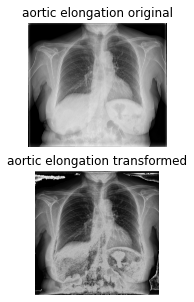

In [12]:
print('---------------Image size--------------------')
print('Original image size:', image_original.shape)
print('Cropped image size:', image_cropped.shape)
print('Equalized image size:', image_eq.shape)
print('Transformed image size:', img_trans.cpu().squeeze()[0].numpy().shape)
print('-------------------------------------------')

# Plot: Original image
figure = plt.figure(figsize=(5, 5))
figure.add_subplot(2, 1, 1)
plt.title(label_list[0] + ' original')
plt.axis("off")
plt.imshow(image_original.squeeze(), cmap = 'gray')

# Plot: Transformed image
figure.add_subplot(2, 1, 2)
plt.title(label_list[0] + ' transformed')
plt.axis("off")
plt.imshow(img_trans.cpu().squeeze()[0].numpy(), cmap = 'gray')

<h1/>Run the inference</h1>

In [13]:
output= model(img_trans)
h_x = F.softmax(output, dim=1).data.squeeze()
prob = h_x.cpu().numpy()

In [14]:
#Obtain the probabilities of each class
probs = (torch.nn.functional.softmax(output, dim=1)[0] * 100).tolist()

# determine the most probable class
class_labels = ["abnormal","normal"]
mostProbableClass = class_labels[probs.index(max(probs))]

print(f"The prediction is {mostProbableClass} with a probability of {max(probs)} %" )

The prediction is abnormal with a probability of 81.39848327636719 %
